# 05 — Modelagem, Validação e Interpretação (Fase 3)

Lê os artefatos produzidos por `python -m src.modeling.treinar` — não
re-treina (o treino completo leva ~20 minutos: busca de hiperparâmetros,
comparação de 4 candidatos em validação cruzada agrupada, predições
out-of-fold e modelo final). Todos os números abaixo são lidos dos arquivos,
não digitados.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100

R = json.loads((ROOT / "reports" / "metricas_modelo.json").read_text(encoding="utf-8"))
print("Modelo escolhido:", R["modelo_escolhido"])
print("Critério:", R["criterio_escolha"])
print("Justificativa:", R["justificativa_escolha"])

Modelo escolhido: regressao_logistica
Critério: regra de 1 desvio padrão sobre a ROC-AUC da validação cruzada agrupada por município
Justificativa: mais simples dentro de 1 desvio padrão do melhor (hist_gradient_boosting: 0.6520 ± 0.0168; regressao_logistica: 0.6480)


## 1. O pipeline

Um único `Pipeline` do scikit-learn: pré-processamento + modelo. Tudo que é
aprendido (medianas, categorias, escalas) é aprendido só no treino de cada
fold — nada vaza para validação/teste.

In [2]:
import joblib
modelo = joblib.load(ROOT / "models" / "modelo_final.joblib")
modelo

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessador', ...), ('classificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['rede_label','escola_n_alunos','mun_n_alunos_ant',...,'idhm_renda', 'capital_uf','amazonia_legal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('cont', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By 

## 2. Desenho da validação

In [3]:
print(f"Treino: {R['n_treino']:,} alunos | Teste: {R['n_teste']:,} alunos de {R['n_municipios_teste']:,} municípios NUNCA vistos")
vc = R["validacao_comparada"]
print(f"\nMesma validação cruzada, dois desenhos:")
print(f"  split aleatório por aluno:      ROC-AUC {vc['split_aleatorio_por_aluno']}")
print(f"  split agrupado por município:   ROC-AUC {vc['split_agrupado_por_municipio']}")
print(f"  otimismo do split aleatório:    {vc['otimismo_split_aleatorio']:+.4f}")

Treino: 1,481,522 alunos | Teste: 370,330 alunos de 1,164 municípios NUNCA vistos

Mesma validação cruzada, dois desenhos:
  split aleatório por aluno:      ROC-AUC 0.6513
  split agrupado por município:   ROC-AUC 0.648
  otimismo do split aleatório:    +0.0033


O split agrupado por município é o que mede a pergunta real ("funciona num
município novo?"). A diferença entre os dois desenhos é o quanto um split
aleatório por aluno superestimaria o resultado.

## 3. Busca de hiperparâmetros e comparação de modelos

Melhores configurações do HistGradientBoosting (RandomizedSearchCV, CV agrupada, 3 folds):


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
0,1,0.649738,0.004610,16.587444,"{'classificador__min_samples_leaf': 2000, 'cla..."
1,2,0.648354,0.005484,13.589731,"{'classificador__min_samples_leaf': 2000, 'cla..."
2,3,0.647921,0.005558,11.402610,"{'classificador__min_samples_leaf': 20, 'class..."
3,4,0.647229,0.006394,29.595410,"{'classificador__min_samples_leaf': 20, 'class..."
4,5,0.645010,0.004002,13.367627,"{'classificador__min_samples_leaf': 100, 'clas..."


Regularização da Regressão Logística (GridSearchCV sobre C, CV agrupada, 3 folds):


,rank_test_score,mean_test_score,std_test_score,mean_fit_time,params
0,1,0.647511,0.003146,1.499574,{'classificador__C': 0.01}
1,2,0.647486,0.002936,1.258981,{'classificador__C': 0.001}
2,3,0.647483,0.003211,1.205446,{'classificador__C': 0.1}
3,4,0.647427,0.003265,1.203063,{'classificador__C': 10.0}
4,5,0.647417,0.003273,1.215254,{'classificador__C': 1.0}


,cv_roc_auc_medio,cv_roc_auc_desvio,treino_roc_auc_medio,gap_treino_validacao,tempo_fit_medio_s
modelo,,,,,
baseline_prevalencia,0.5000,0.0000,0.5000,0.0000,0.8
regressao_logistica,0.6480,0.0162,0.6515,0.0035,1.4
random_forest,0.6514,0.0150,0.6873,0.0359,13.2
hist_gradient_boosting,0.6520,0.0168,0.6853,0.0333,18.0


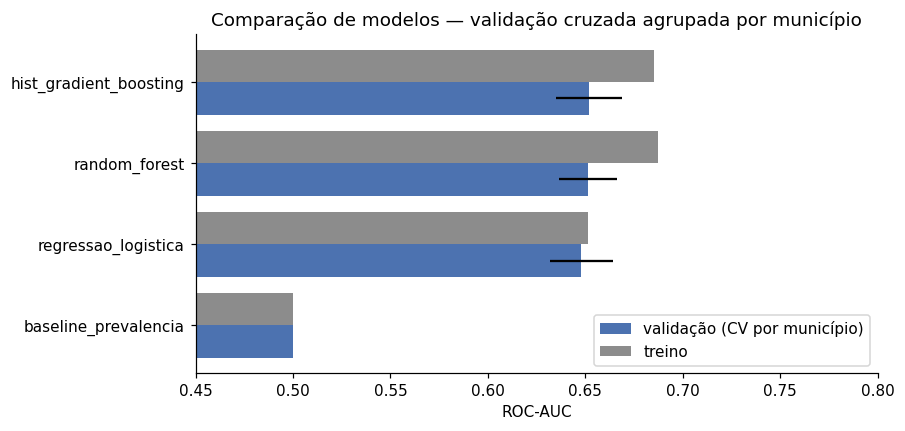

In [4]:
tuning = pd.read_csv(ROOT / "reports" / "tuning_hist_gradient_boosting.csv")
print("Melhores configurações do HistGradientBoosting (RandomizedSearchCV, CV agrupada, 3 folds):")
display(tuning.head(5))
tuning_lr = pd.read_csv(ROOT / "reports" / "tuning_regressao_logistica.csv")
print("Regularização da Regressão Logística (GridSearchCV sobre C, CV agrupada, 3 folds):")
display(tuning_lr)
comparacao = pd.DataFrame(R["comparacao_modelos"]).set_index("modelo")
display(comparacao)
display(Image(filename=str(ROOT / "images" / "04_comparacao_modelos.png")))

Regra de escolha (D14): entre os modelos a até 1 desvio padrão do melhor,
fica o mais simples. Diferenças menores que a variação entre folds não são
evidência de que o modelo mais complexo generaliza melhor — e o gap
treino-validação (coluna `gap_treino_validacao`) mostra quem está mais
perto de overfitting.

In [5]:
por_fold = pd.read_csv(ROOT / "reports" / "comparacao_modelos_por_fold.csv", index_col="fold")
display(por_fold.round(4))
for par, r in R["comparacao_pareada"].items():
    print(f"{par:55s} diferença média {r['diferenca_media']:+.4f}  IC95% {r['ic95_aprox']}  "
          f"(melhor em {r['folds_a_melhor']} de {r['n_folds']} folds)")

,baseline_prevalencia,regressao_logistica,random_forest,hist_gradient_boosting
fold,,,,
0,0.5,0.6365,0.6426,0.6414
1,0.5,0.6561,0.6589,0.6578
2,0.5,0.6580,0.6611,0.6630
3,0.5,0.6671,0.6679,0.6727
4,0.5,0.6225,0.6263,0.6253


random_forest_menos_regressao_logistica                 diferença média +0.0033  IC95% [0.0009, 0.0057]  (melhor em 5 de 5 folds)
hist_gradient_boosting_menos_regressao_logistica        diferença média +0.0040  IC95% [0.0019, 0.0061]  (melhor em 5 de 5 folds)


**Comparação pareada.** Os candidatos foram avaliados nos *mesmos* folds,
então dá para comparar fold a fold — o que remove a variação entre grupos de
municípios (mais fáceis ou mais difíceis), que afeta todos os modelos igual.
Se o intervalo de 95% da diferença inclui zero, não há evidência estatística
de que o modelo mais complexo seja melhor; se exclui zero mas a diferença é
pequena (milésimos de AUC), ela não paga o gap de overfitting maior e a perda
de interpretabilidade — é o que a regra de 1 desvio padrão formaliza.

In [6]:
sens = json.loads((ROOT / "reports" / "sensibilidade_modelo.json").read_text(encoding="utf-8"))
display(pd.DataFrame(sens["comparacao_no_teste"]).set_index("modelo"))
print(f"Sobreposição dos 20% de municípios de maior risco entre os dois modelos: {sens['sobreposicao_top20_municipios']:.0%}")
print(f"Correlação entre as taxas municipais previstas pelos dois: {sens['correlacao_taxas_municipais_entre_modelos']}")

,roc_auc,brier,lift_top20,correlacao_municipal,mae_municipal_pp
modelo,,,,,
regressao_logistica,0.6276,0.2286,1.452,0.7299,9.64
hist_gradient_boosting,0.6344,0.2275,1.454,0.7696,8.92


Sobreposição dos 20% de municípios de maior risco entre os dois modelos: 84%
Correlação entre as taxas municipais previstas pelos dois: 0.934


**Sensibilidade (D21).** Checagem posterior à escolha: o HGB treinado no
mesmo treino e avaliado no mesmo teste. Os dois priorizam os mesmos alunos
(lift praticamente idêntico) e quase os mesmos municípios; o HGB é um pouco
melhor no agregado municipal. A escolha não foi revista — mudar de modelo
depois de ver o teste invalidaria o teste — e o HGB fica como **modelo
desafiante** para a próxima rodada com dados novos.

## 4. Resultado no teste (municípios nunca vistos)

In [7]:
t, b = R["metricas_teste"], R["metricas_baseline_teste"]
tabela = pd.DataFrame({"modelo": t, "baseline": b}).drop("matriz_confusao")
display(tabela)
print(f"ROC-AUC treino {R['roc_auc_treino']} vs teste {t['roc_auc']} (gap {R['roc_auc_treino'] - t['roc_auc']:.4f})")
print(f"ROC-AUC out-of-fold em TODOS os municípios (5 folds agrupados): {R['roc_auc_oof_todos_alunos']}")
bt = R["bootstrap_teste"]
print(f"IC 95% do ROC-AUC no teste (bootstrap de {bt['n_boot']} reamostragens por {bt['unidade_reamostrada']}): "
      f"{bt['roc_auc_ic95']}")
print(f"IC 95% do lift no top 20%: {bt['lift_top20_ic95']}")

,modelo,baseline
roc_auc,0.6276,0.5
average_precision,0.7081,0.5979
brier,0.2286,0.2404
acuracia,0.63,0.5979
precisao,0.6457,0.5979
recall,0.8444,1.0
f1,0.7318,0.7484
precisao_risco,0.5736,0.0
recall_risco,0.3111,0.0
f1_risco,0.4034,0.0


ROC-AUC treino 0.6516 vs teste 0.6276 (gap 0.0240)
ROC-AUC out-of-fold em TODOS os municípios (5 folds agrupados): 0.6452
IC 95% do ROC-AUC no teste (bootstrap de 300 reamostragens por município): [0.5941, 0.6547]
IC 95% do lift no top 20%: [1.3579, 1.4918]


**Intervalo de confiança.** O bootstrap reamostra **municípios inteiros**,
não alunos — alunos do mesmo município compartilham o contexto e não são
independentes; reamostrá-los um a um daria um intervalo artificialmente
estreito. O intervalo inteiro fica bem acima de 0,5 (baseline) e o do lift
bem acima de 1: o ganho sobre o acaso é estatisticamente robusto.

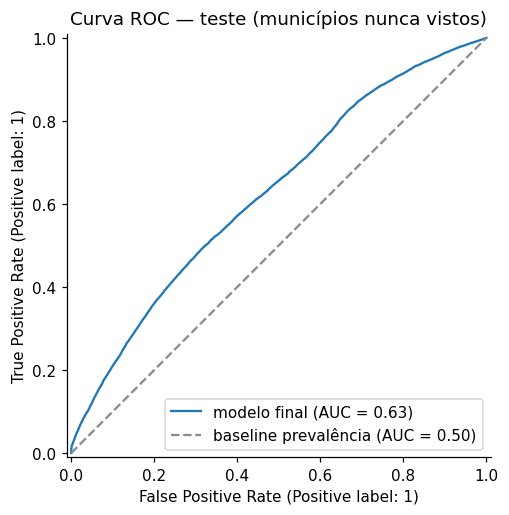

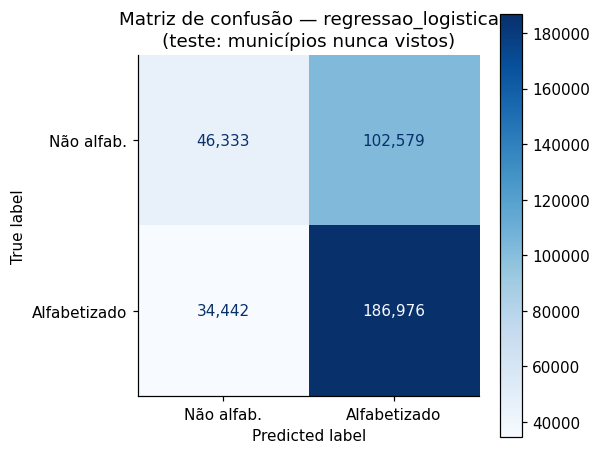

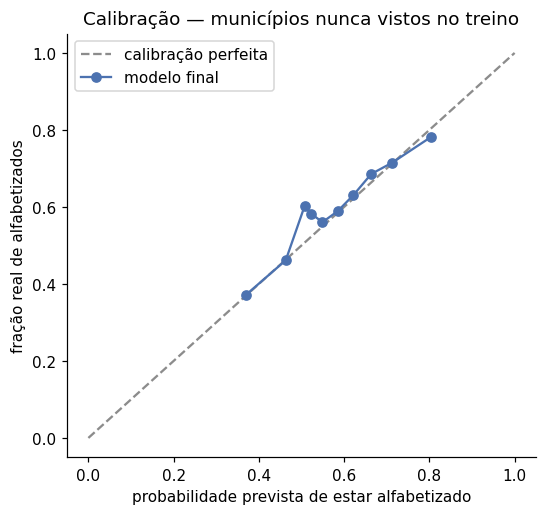

In [8]:
for img in ["06_curva_roc.png", "05_matriz_confusao.png", "07_calibracao.png"]:
    display(Image(filename=str(ROOT / "images" / img)))

Calibração: os pontos perto da diagonal significam que uma probabilidade
prevista de 60% corresponde a ~60% de alfabetizados — condição para somar
probabilidades por município e comparar com metas (notebook 06).

## 5. Uso operacional: priorização em vez de limiar fixo

,fracao_priorizada,limiar_p_risco,taxa_risco_no_grupo,recall_risco,lift
0,0.05,0.6239,0.6559,0.0816,1.631
1,0.10,0.5767,0.6291,0.1565,1.565
2,0.20,0.5086,0.5839,0.2904,1.452
3,0.30,0.4836,0.5220,0.3895,1.298
4,0.50,0.4348,0.4845,0.6025,1.205


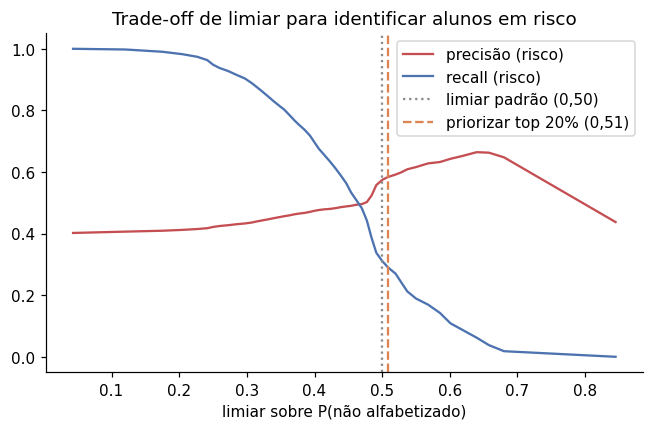

In [9]:
prior = pd.read_csv(ROOT / "reports" / "analise_priorizacao.csv")
display(prior)
display(Image(filename=str(ROOT / "images" / "08_tradeoff_limiar.png")))

Lida linha a linha: se um programa de reforço só pode atender X% dos
alunos, atendendo os X% de maior risco previsto ele encontra a fração
`taxa_risco_no_grupo` de alunos de fato em risco — `lift` vezes mais do que
escolhendo ao acaso.

## 6. Interpretabilidade e teste das hipóteses

Quatro olhares complementares: **coeficientes** (feature importance nativa do
modelo linear), **importância por permutação** (impacto na métrica, fora da
amostra), **SHAP** (direção e magnitude por aluno) e **ablação por grupo**
(retreina sem cada grupo de fatores — robusta a features correlacionadas).

,feature,coeficiente
0,taxa_alfabetizacao_ant,0.386343
1,rede_label_Estadual,0.329232
2,prof_media_ant,0.318901
3,meta_ano,-0.177023
4,participacao_ant,0.114678
5,prof_p25_ant,-0.081467
6,idhm_educacao,0.065738
7,mun_n_alunos_ant,-0.059330
8,nivel_alfabetizacao_ant,0.057332
9,esforco_meta,-0.050833


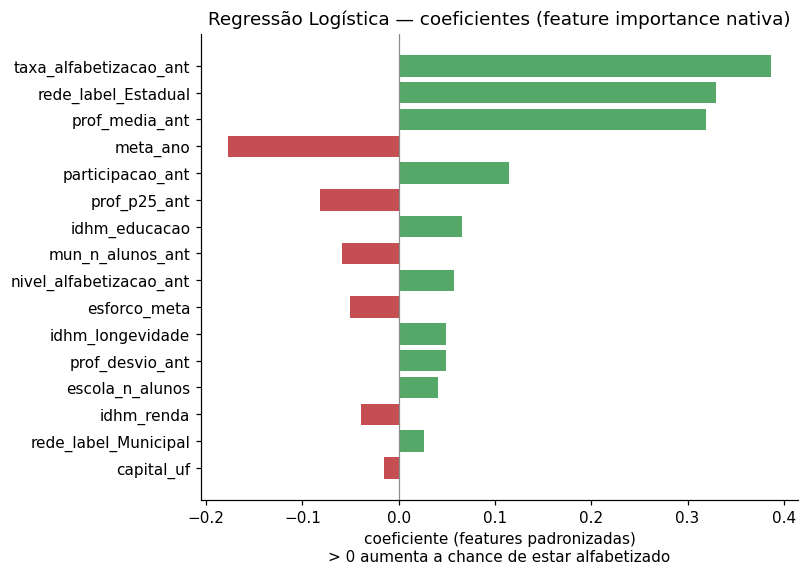

In [10]:
coefs = pd.read_csv(ROOT / "reports" / "coeficientes_regressao_logistica.csv")
display(coefs[~coefs.feature.str.startswith("missingindicator")].head(10))
display(Image(filename=str(ROOT / "images" / "18_coeficientes_logistica.png")))

,feature,queda_roc_auc,desvio
0,taxa_alfabetizacao_ant,0.071090,0.001818
1,prof_media_ant,0.034572,0.001196
2,participacao_ant,0.004508,0.000293
3,idhm_educacao,0.004372,0.000180
4,meta_ano,0.002376,0.000640
5,idhm_longevidade,0.002204,0.000139
6,nivel_alfabetizacao_ant,0.001558,0.000230
7,prof_desvio_ant,0.001449,0.000157
8,rede_label,0.000956,0.000456
9,esforco_meta,0.000949,0.000183


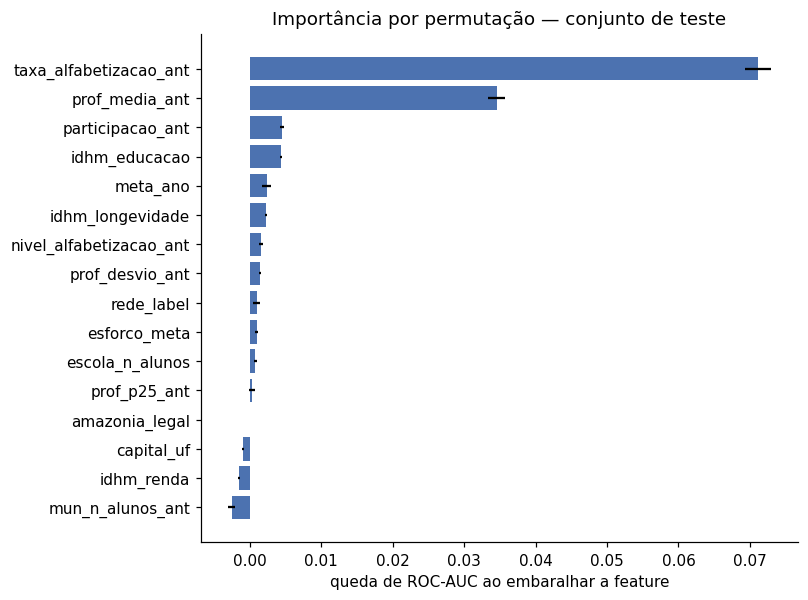

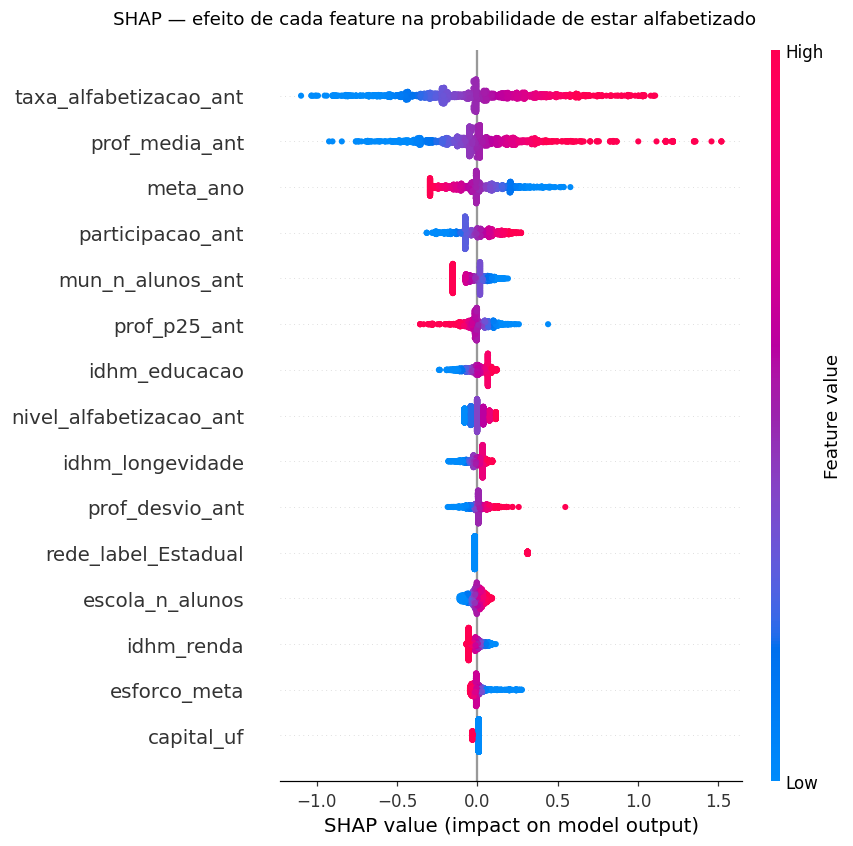

In [11]:
perm = pd.read_csv(ROOT / "reports" / "importancia_permutacao.csv")
shap_imp = pd.read_csv(ROOT / "reports" / "shap_importance.csv")
display(perm.head(10))
display(Image(filename=str(ROOT / "images" / "09_importancia_permutacao.png")))
display(Image(filename=str(ROOT / "images" / "10_shap_summary.png")))

In [12]:
ranking = perm.set_index("feature")["queda_roc_auc"]
educacionais = ["taxa_alfabetizacao_ant", "prof_media_ant", "prof_p25_ant", "nivel_alfabetizacao_ant",
                "participacao_ant", "prof_desvio_ant"]
idhm = ["idhm_educacao", "idhm_renda", "idhm_longevidade"]
print("H1 — feature mais importante:", ranking.idxmax(), f"(queda de ROC-AUC {ranking.max():.4f})")
print(f"H2 — soma da importância: históricos educacionais {ranking[educacionais].sum():.4f} | IDHM {ranking[idhm].sum():.4f}")
coef = pd.Series(modelo.named_steps["classificador"].coef_[0] if hasattr(modelo.named_steps["classificador"], "coef_") else [],
                 dtype=float)
if len(coef):
    nomes = modelo.named_steps["preprocessador"].get_feature_names_out()
    coef.index = [n.split("__", 1)[-1] for n in nomes]
    print(f"H3 — coeficiente de esforco_meta (padronizado): {coef['esforco_meta']:+.4f}")

H1 — feature mais importante: taxa_alfabetizacao_ant (queda de ROC-AUC 0.0711)
H2 — soma da importância: históricos educacionais 0.1135 | IDHM 0.0051
H3 — coeficiente de esforco_meta (padronizado): -0.0643


**H1 — confirmada.** A taxa de alfabetização do município no ano anterior
é, isoladamente, a feature mais importante; a proficiência média do ano
anterior vem em segundo. Juntas respondem pela maior parte da capacidade de
separação do modelo.

**H2 — confirmada, com folga.** A soma da importância dos históricos
educacionais é mais de 20× a dos componentes do IDHM. Isso **não** quer
dizer que condição socioeconômica não importa — ela já está "embutida" no
resultado educacional passado do município. Quer dizer que, para prever o
próximo ano, o histórico educacional carrega quase toda a informação que o
IDHM traria, e mais.

**H3 — confirmada na direção, fraca na magnitude.** O coeficiente de
`esforco_meta` é negativo (mais esforço necessário → menor chance), mas a
contribuição marginal é pequena: a correlação simples de −0,20 vista no
notebook 04 é, em boa parte, explicada pelo próprio resultado passado (quem
precisa de mais esforço é quem teve resultado mais baixo).

Coeficientes da regressão logística são interpretáveis aqui porque as
redundâncias por construção foram removidas (IDHM composto e taxa da rede
municipal — ver D7 em `docs/decisoes_analiticas.md`). Antes disso, o IDHM
saía com coeficiente −1,19 compensando os componentes positivos.

Observação: `mun_n_alunos_ant`, `idhm_renda` e `capital_uf` têm importância
por permutação levemente **negativa** no teste — embaralhá-las melhora a
ROC-AUC em ~0,001–0,003. É um sinal de que não ajudam a generalizar para
municípios novos. Não foram removidas com base nisso, porque seria escolher
features olhando o teste; fica como candidata a seleção de features por
validação cruzada (evolução futura).

**H4** e **H5**: testadas no notebook 06 (agregação municipal e clusters).

### Ablação por grupo de fatores

A permutação mede uma feature por vez — e subestima um **grupo** quando as
outras features do grupo carregam a mesma informação (ex.: taxa e
proficiência do ano anterior). A ablação retreina o modelo em validação
cruzada agrupada **sem** cada grupo e **só** com ele.

ROC-AUC com todas as features: 0.648


,grupo,n_features,roc_auc_sem_o_grupo,perda_ao_remover,roc_auc_so_o_grupo
0,Histórico educacional do município (ano anterior),6,0.6403,0.0077,0.6439
1,Escola e rede,2,0.6452,0.0028,0.5084
2,IDHM (socioeconômico),3,0.6478,0.0002,0.5392
3,Meta e esforço para atingi-la,2,0.6479,0.0001,0.6278
4,Território e porte do município,3,0.6480,-0.0000,0.5353


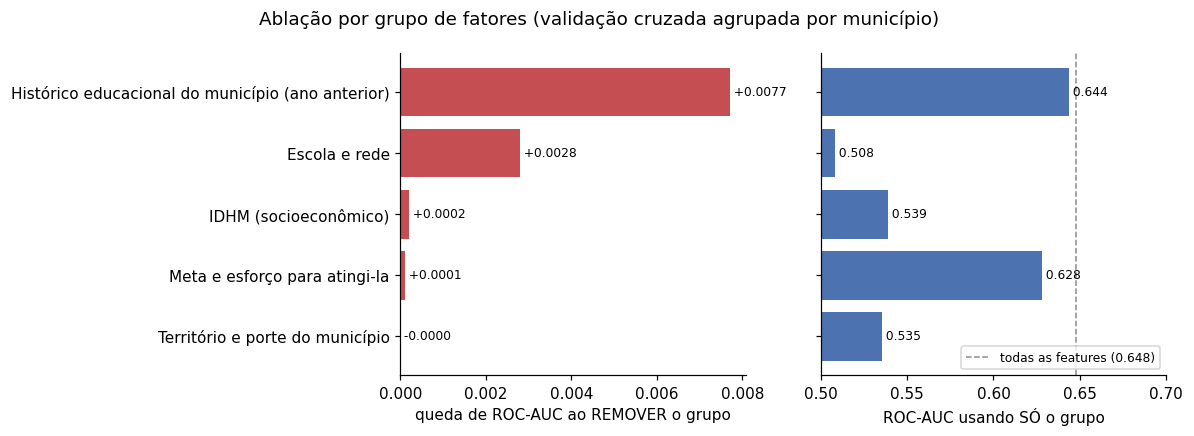

In [13]:
abl = pd.read_csv(ROOT / "reports" / "ablacao_grupos_features.csv")
print("ROC-AUC com todas as features:", R["ablacao"]["roc_auc_completo"])
display(abl)
display(Image(filename=str(ROOT / "images" / "19_ablacao_grupos.png")))

Leitura: o grupo cuja remoção mais derruba a ROC-AUC é o fator que mais
impacta a predição — e o que, sozinho, chega mais perto do modelo completo é
o que carrega quase toda a informação. É a resposta mais robusta à pergunta
de negócio "quais fatores mais impactam a alfabetização?".

## 7. Onde o modelo funciona pior

,nome_regiao,n_alunos,taxa_real,taxa_prevista,roc_auc
0,Sudeste,154743,62.9,57.5,0.5822
1,Norte,28237,51.8,51.0,0.6058
2,Centro-Oeste,24057,67.6,63.6,0.6073
3,Sul,55031,63.1,66.3,0.6141
4,Nordeste,108262,54.0,55.1,0.6676


,rede_label,n_alunos,taxa_real,taxa_prevista,roc_auc
0,Estadual,25890,60.8,64.3,0.5688
1,Municipal,344440,59.7,57.5,0.6317


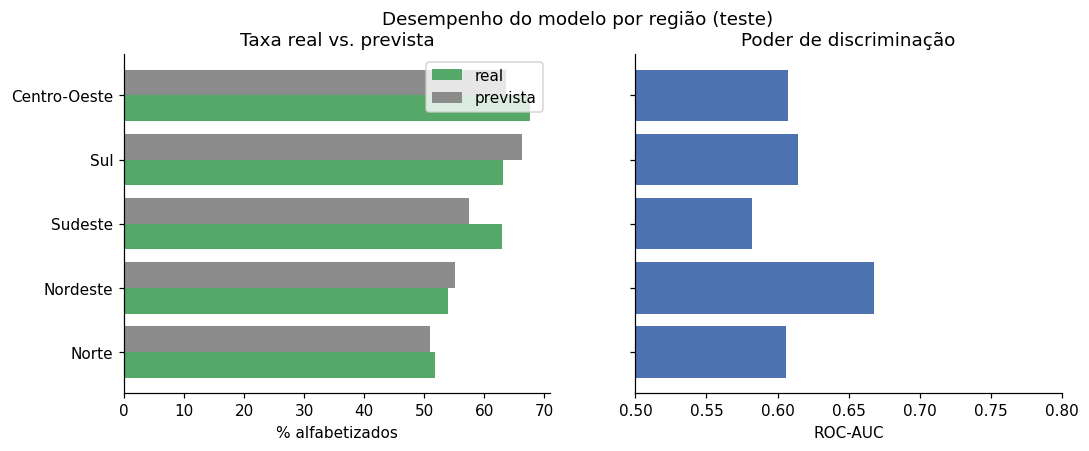

In [14]:
for arquivo in ["desempenho_por_nome_regiao.csv", "desempenho_por_rede_label.csv"]:
    display(pd.read_csv(ROOT / "reports" / arquivo))
display(Image(filename=str(ROOT / "images" / "11_desempenho_regiao.png")))

Diferenças entre taxa real e prevista por região mostram onde o modelo
erra de forma sistemática — como UF/região ficaram fora das features (D8),
um viés regional residual é esperado e é documentado em vez de "corrigido"
com uma variável que não transfere para o ano seguinte.